# Lohoff Figure 2c recreation

Run TissueAgent to recreate the three germ-layer panels from the supplied seqFISH data and canonical reference. Each panel contains all **19,416 cells** at their original spatial coordinates; the matching germ-layer cell types are highlighted and other cells are gray. No color-map file is supplied, so approximated colors and any inferred scale calibration must be documented.

The notebook displays only the explicitly named accepted final figure. Diagnostic cell-type grids are separate artifacts and are never selected for display.


In [1]:
from pathlib import Path
import hashlib
import json
import os
import shutil
import socket
import subprocess
import sys
from datetime import datetime, timezone

from IPython.display import Image, display

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "pyproject.toml").exists():
    REPO_ROOT = REPO_ROOT.parent
assert (REPO_ROOT / "pyproject.toml").exists(), "Run this notebook from demo/ or the repository root."

TASK_NAME = "figure_recreation_lohoff-2c_refined"
TASK_ID = "notebook_lohoff_2c_no_colormap"
MODEL = "gpt-5.5"
DATA_DIR = REPO_ROOT / "demo/data"
DATASETS = [DATA_DIR / "dataset_lohoff_et_al_seqfish.h5ad"]
REFERENCE = DATA_DIR / "reference_lohoff-2c.png"
ATTACHMENTS = [REFERENCE]
INPUTS = [*DATASETS, *ATTACHMENTS]
OUTPUT_DIR = REPO_ROOT / "demo/outputs" / TASK_NAME
PROMPT = "I have provided a spatial transcriptomics dataset in dataset_lohoff_et_al_seqfish.h5ad. Recreate Lohoff Figure 2c as exactly three side-by-side panels titled Ectoderm, Mesoderm, and Endoderm, using reference_lohoff-2c.png as the visual target. The dataset contains 19,416 cells and already represents the tissue section shown in the reference. Use obsm['spatial'] for the original cell coordinates and obs['celltype_mapped_refined'] for the existing labels. In each panel show all 19,416 cells, with that germ layer's cell types highlighted in their reference-guided colors and all remaining cells in light gray. Retain Low quality cells as gray background. Document the cell-type to germ-layer mapping, including treatment of ambiguous NMP cells, and all approximate colors. Preserve coordinates and a common spatial scale across the panels; invert the y-axis to match the reference. Include the panel label c, 250 micrometer scale annotation, and A/P/D/V orientation cross. Verify any spatial-unit conversion before claiming a calibrated scale bar; disclose any calibration inferred from the reference. Match the overall panel geometry, titles, point density, background, and highlighted structures as closely as the supplied data support. Do not replace the three-panel figure with per-cell-type diagnostics, filter or reposition cells for visual similarity, or retrieve earlier TissueAgent or baseline reproductions. Work only from the provided inputs. Save the accepted final figure at outputs/final_figure.png and outputs/final_figure.pdf; these files must contain the requested complete multi-panel figure, not diagnostic plots. Also save executable plotting code, outputs/tables/plotted_data.csv, outputs/tables/colormap.yaml, and outputs/reports/reproduction_report.md. The plotted-data table must contain columns panel, cell, x, y, celltype, with the original input cell identifier, unmodified input coordinates, and original cell-type label for each plotted cell. Record axis inversion in the report, not by changing exported coordinates. Inspect the accepted final PNG against the supplied reference before completing. Never copy reference-image pixels into the generated figure."
PROMPT += ' Final visual acceptance must check the specific prominent structures in the supplied reference, not just the panel count or a global similarity score. In the Mesoderm reference the distinct right-side Presomitic mesoderm block is bright yellow-green, not rust/brown; the broad right-hand Lateral plate mesoderm stripe is purple/lavender, not orange; the curved Cardiomyocytes ring is magenta-purple. Verify the other mesoderm category colors against the actual reference using their spatial distributions, rather than assigning an unrelated generic palette. In Ectoderm the neural tissue is dark olive, with pale yellow/green spinal and surface ectoderm regions; Endoderm is predominantly pink. These are visual constraints from the supplied reference, not an authoritative author color map. Document the approximations and ambiguous assignments. Match the reference canvas (1660 by 802 pixels). The tissue point clouds extend approximately from y=115 to y=748 image pixels; their left edges are around x=85, x=587, and x=1073, with widths approximately 420 pixels. Use consistent axes limits and display scale across all three panels, and document any common display-aspect adjustment; never transform individual cells. Place the 250 micrometer annotation near the lower right of Ectoderm (bar around image x=425..527, y=719), and the orientation cross at the far lower right. Increase point coverage enough to match the dense gray background without changing the cell set. Before finalizing, inspect both the accepted final PNG and an aligned comparison, and correct these specific color, density, and layout mismatches if present.'
ROLES = {DATASETS[0].name: "dataset", REFERENCE.name: "reference"}

INPUT_RECORDS = []
for path in INPUTS:
    assert path.is_file(), f"Missing input: {path}"
    with path.open("rb") as stream:
        digest = hashlib.file_digest(stream, "sha256").hexdigest()
    INPUT_RECORDS.append({"role": ROLES[path.name], "path": str(path), "name": path.name, "sha256": digest})

print(json.dumps({
    "task": TASK_NAME,
    "datasets": [str(path) for path in DATASETS],
    "attachments": [str(path) for path in ATTACHMENTS],
    "supplied_colormap": False,
    "expected_cells_per_panel": 19416,
    "output_dir": str(OUTPUT_DIR),
}, indent=2))


{
  "task": "figure_recreation_lohoff-2c_refined",
  "datasets": [
    "/Users/wenduoc/new_TissueAgent/TissueAgent/demo/data/dataset_lohoff_et_al_seqfish.h5ad"
  ],
  "attachments": [
    "/Users/wenduoc/new_TissueAgent/TissueAgent/demo/data/reference_lohoff-2c.png"
  ],
  "supplied_colormap": false,
  "expected_cells_per_panel": 19416,
  "output_dir": "/Users/wenduoc/new_TissueAgent/TissueAgent/demo/outputs/figure_recreation_lohoff-2c_refined"
}


## Run the CLI

Set `OPENAI_API_KEY` in the notebook environment. The first run makes model calls and saves the complete trace and execution state under `OUTPUT_DIR`. A completed local run is reused only when its model, prompt, and input checksums match. Choose a new `OUTPUT_DIR` for a fresh run if results already exist or settings change.


In [2]:
manifest_path = OUTPUT_DIR / "run_manifest.json"
metrics_path = OUTPUT_DIR / "metrics.json"
if OUTPUT_DIR.is_dir() and manifest_path.is_file() and metrics_path.is_file():
    manifest = json.loads(manifest_path.read_text())
    metrics = json.loads(metrics_path.read_text())
    terminal_state = metrics.get("outcome", {}).get("terminal_state")
    expected_hashes = {record["name"]: record["sha256"] for record in INPUT_RECORDS}
    cached_hashes = {record["name"]: record["sha256"] for record in manifest["inputs"]}
    assert terminal_state == "completed" and manifest.get("cli_exit_code") == 0
    assert manifest.get("supplied_colormap") is False
    assert manifest.get("prompt") == PROMPT, "Prompt changed; choose a new OUTPUT_DIR."
    assert manifest.get("model") == MODEL, "Model changed; choose a new OUTPUT_DIR."
    assert cached_hashes == expected_hashes, "Inputs changed; choose a new OUTPUT_DIR."
    print(json.dumps({
        "terminal_state": terminal_state,
        "elapsed_seconds": manifest["elapsed_seconds"],
        "output_dir": str(OUTPUT_DIR),
        "reused_completed_output": True,
    }, indent=2))
else:
    if OUTPUT_DIR.exists():
        raise RuntimeError(f"{OUTPUT_DIR} already exists. Choose a new OUTPUT_DIR for a fresh run.")
    assert os.environ.get("OPENAI_API_KEY"), "Set OPENAI_API_KEY in the notebook environment for a fresh run."
    OUTPUT_DIR.mkdir(parents=True)
    STATE_ROOT = OUTPUT_DIR / "state"
    with socket.socket() as sock:
        sock.bind(("127.0.0.1", 0))
        gateway_port = sock.getsockname()[1]
    env = os.environ.copy()
    env.update({
        "TISSUEAGENT_STATE_ROOT": str(STATE_ROOT),
        "TISSUEAGENT_GATEWAY_PORT": str(gateway_port),
        "TISSUEAGENT_ORCHESTRATION_REASONING_EFFORT": "medium",
        "TISSUEAGENT_WORKER_REASONING_EFFORT": "high",
        "NUMBA_CACHE_DIR": str(OUTPUT_DIR / "cache/numba"),
        "MPLCONFIGDIR": str(OUTPUT_DIR / "cache/matplotlib"),
        "XDG_CACHE_HOME": str(OUTPUT_DIR / "cache/xdg"),
        "IPYTHONDIR": str(OUTPUT_DIR / "cache/ipython"),
        "JUPYTER_RUNTIME_DIR": str(OUTPUT_DIR / "cache/jupyter_runtime"),
        "PYTHONPATH": str(REPO_ROOT / "src") + os.pathsep + str(REPO_ROOT),
        "PATH": str(Path(sys.executable).parent) + os.pathsep + env.get("PATH", ""),
    })
    for key in ["NUMBA_CACHE_DIR", "MPLCONFIGDIR", "XDG_CACHE_HOME", "IPYTHONDIR", "JUPYTER_RUNTIME_DIR"]:
        Path(env[key]).mkdir(parents=True, exist_ok=True)
    command = [
        sys.executable, "-m", "cli", "--no-docker", "--json", "--model", MODEL,
        "--task-id", TASK_ID, "--seed", "0", "--attempt", "1",
        "--metrics-out", str(metrics_path),
    ]
    for dataset in DATASETS:
        command.extend(["--dataset", str(dataset)])
    for attachment in ATTACHMENTS:
        command.extend(["--attach", str(attachment)])
    command.append("-")

    transcript_path = OUTPUT_DIR / "transcript.log"
    (OUTPUT_DIR / "prompt.txt").write_text(PROMPT + "\n")
    started_at = datetime.now(timezone.utc)
    with transcript_path.open("w") as transcript:
        completed = subprocess.run(
            command, input=PROMPT, cwd=REPO_ROOT, env=env,
            stdout=transcript, stderr=subprocess.STDOUT, text=True, check=False,
        )
    finished_at = datetime.now(timezone.utc)
    project_dir = STATE_ROOT / "workspace/project"
    project_outputs = project_dir / "outputs"
    if project_outputs.is_dir():
        for source in project_outputs.iterdir():
            destination = OUTPUT_DIR / source.name
            if source.is_dir():
                shutil.copytree(source, destination, dirs_exist_ok=True)
            else:
                shutil.copy2(source, destination)
    if (project_dir / "metrics.json").is_file():
        shutil.copy2(project_dir / "metrics.json", OUTPUT_DIR / "project_metrics.json")
    if not metrics_path.is_file():
        raise RuntimeError(f"CLI exited {completed.returncode} without metrics. See {transcript_path}; state retained at {STATE_ROOT}.")
    metrics = json.loads(metrics_path.read_text())
    terminal_state = metrics.get("outcome", {}).get("terminal_state")
    manifest = {
        "task": TASK_NAME, "task_id": TASK_ID, "model": MODEL,
        "started_at_utc": started_at.isoformat(),
        "finished_at_utc": finished_at.isoformat(),
        "elapsed_seconds": metrics.get("run", {}).get("wall_time_s", (finished_at - started_at).total_seconds()),
        "elapsed_seconds_definition": "CLI-reported workflow wall time, falling back to subprocess wall time",
        "command": command, "prompt": PROMPT, "inputs": INPUT_RECORDS,
        "supplied_colormap": False, "cli_exit_code": completed.returncode,
        "terminal_state": terminal_state, "state_root": str(STATE_ROOT),
    }
    manifest_path.write_text(json.dumps(manifest, indent=2) + "\n")
    if completed.returncode != 0 or terminal_state != "completed":
        raise RuntimeError(f"CLI failed (exit={completed.returncode}, terminal_state={terminal_state}). See {transcript_path}; state retained at {STATE_ROOT}.")
    print(json.dumps({"terminal_state": terminal_state, "elapsed_seconds": manifest["elapsed_seconds"], "output_dir": str(OUTPUT_DIR)}, indent=2))


{
  "terminal_state": "completed",
  "elapsed_seconds": 403.8,
  "output_dir": "/Users/wenduoc/new_TissueAgent/TissueAgent/demo/outputs/figure_recreation_lohoff-2c_refined"
}


## Validate the plotted data

Check cell identities, labels, and original coordinates before displaying the final figure.


In [3]:
import anndata as ad
import numpy as np
import pandas as pd

plotted = pd.read_csv(OUTPUT_DIR / "tables/plotted_data.csv", dtype={"cell": str})
assert {"panel", "cell", "x", "y", "celltype"} <= set(plotted.columns)
adata = ad.read_h5ad(DATASETS[0], backed="r")
try:
    expected = pd.DataFrame(adata.obsm["spatial"], index=adata.obs_names.astype(str), columns=["x", "y"])
    expected["celltype"] = adata.obs["celltype_mapped_refined"].astype(str).to_numpy()
finally:
    adata.file.close()
expected = expected.sort_index()
assert len(expected) == 19416
assert set(plotted["panel"]) == {"Ectoderm", "Mesoderm", "Endoderm"}
for panel in ("Ectoderm", "Mesoderm", "Endoderm"):
    actual = plotted.loc[plotted["panel"] == panel].set_index("cell").sort_index()
    assert actual.index.is_unique and actual.index.equals(expected.index), panel
    assert actual["celltype"].equals(expected["celltype"]), panel
    np.testing.assert_allclose(actual[["x", "y"]], expected[["x", "y"]], rtol=0, atol=1e-8)
print("Verified all 19,416 cells, original labels, and original spatial coordinates in each panel.")
display(plotted.groupby("panel").size().rename("Plotted cells").to_frame())


Verified all 19,416 cells, original labels, and original spatial coordinates in each panel.


,Plotted cells
panel,
Ectoderm,19416
Endoderm,19416
Mesoderm,19416


## Final figure


demo/outputs/figure_recreation_lohoff-2c_refined/final_figure.png


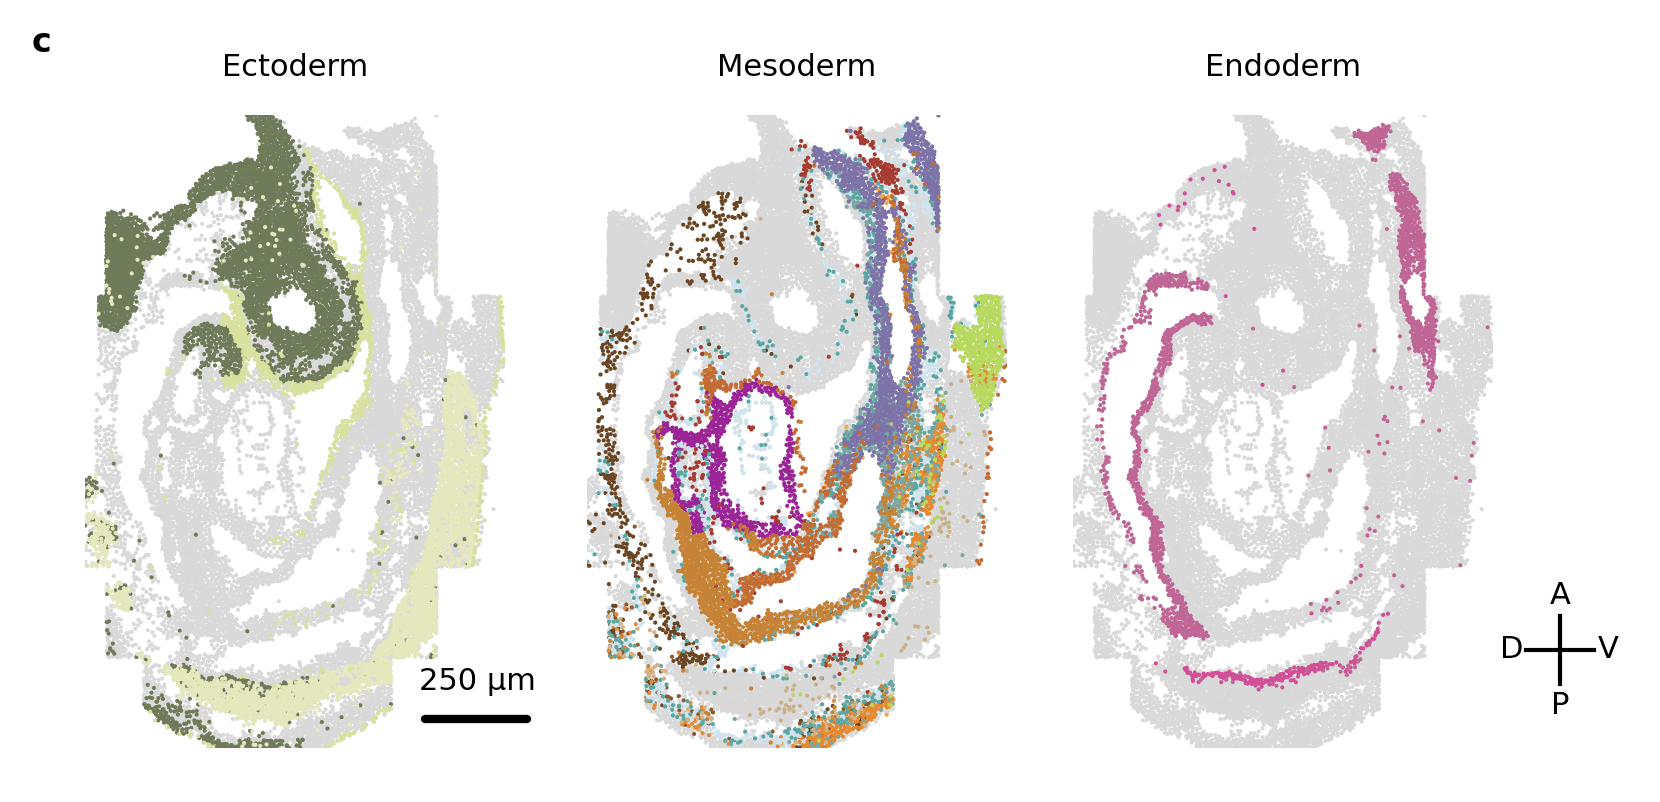

# Lohoff Figure 2c reproduction report

## Inputs and fields used

- Dataset: `library/datasets/dataset_lohoff_et_al_seqfish.h5ad`
- Reference target: `project/uploads/reference_lohoff-2c.png`
- Cell count: 19,416 cells.
- Coordinates: `obsm['spatial']`, used directly for plotting.
- Cell-type labels: `obs['celltype_mapped_refined']`.
- No cells were filtered, repositioned, mirrored, or individually transformed. Each of the three panels plots all 19,416 cells.
- The exported plotted-data table records the original input coordinates. Y-axis inversion is done only in the Matplotlib display (`ylim=(ymax, ymin)`) and is not applied to `outputs/tables/plotted_data.csv`.

## Canvas, geometry, and display scale

- Final canvas: 1660 x 802 pixels, matching the supplied reference.
- Three side-by-side panels titled **Ectoderm**, **Mesoderm**, and **Endoderm**.
- Panel data boxes were set in reference-image pixel coordinates:
  - Ectoderm: left x=85, top y=115, width=420, height=633 px.
  - Meso

In [4]:
selected = OUTPUT_DIR / "final_figure.png"
for path in (selected, OUTPUT_DIR / "final_figure.pdf", OUTPUT_DIR / "tables/colormap.yaml",
             OUTPUT_DIR / "reports/reproduction_report.md"):
    assert path.is_file(), f"Missing required final artifact: {path}. Inspect transcript.log; diagnostics are not final figures."
print(selected.relative_to(REPO_ROOT))
display(Image(filename=str(selected)))
print((OUTPUT_DIR / "reports/reproduction_report.md").read_text())
